# Phase E scratch notebook: points regression
Work in progress for section 6 of the main notebook. Finished cells are copied there.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"

# Same values as the main notebook's config cell. Change them there, not here.
SEED = 363
POSITIONS = ["QB", "RB", "WR", "TE"]
TRAIN_SEASONS = list(range(2020, 2025))
TEST_SEASON = 2025
TARGET = "fantasy_points_ppr"
CV_VALID_SEASONS = [2022, 2023, 2024]
TOP_N = 12

## Shared data
`features` has one row per player-week (2020-2025) with the target. `FEATURE_FAMILIES` lists the only columns that may be used as model inputs. `train` drops 2025, which is only for the final test (Phase H).

In [2]:
features = pd.read_parquet(PROCESSED_DIR / "features.parquet")
FEATURE_FAMILIES = json.loads((PROCESSED_DIR / "feature_families.json").read_text())
ALL_FEATURES = [c for cols in FEATURE_FAMILIES.values() for c in cols]

train = features[features["season"].isin(TRAIN_SEASONS)].reset_index(drop=True)
print(f"train: {train.shape}, features: {len(ALL_FEATURES)}")

train: (18402, 55), features: 48


## Shared evaluation (copied exactly from main notebook section 5.6; a test checks they match)

In [3]:
def cv_folds(data):
    for season in CV_VALID_SEASONS:
        train = data.index[data["season"].between(TRAIN_SEASONS[0], season - 1)]
        valid = data.index[data["season"] == season]
        yield season, train, valid


def top_n_hit_rate(week):
    predicted_top = set(week.nlargest(TOP_N, "pred").index)
    actual_top = set(week.nlargest(TOP_N, TARGET).index)
    return len(predicted_top & actual_top) / TOP_N


def evaluate(data, pred):
    d = data.assign(pred=np.asarray(pred))
    groups = d.groupby(["season", "week", "position"])
    return {
        "rmse": float(np.sqrt(((d["pred"] - d[TARGET]) ** 2).mean())),
        "mae": float((d["pred"] - d[TARGET]).abs().mean()),
        "spearman": float(groups.apply(lambda w: w["pred"].corr(w[TARGET], method="spearman")).mean()),
        "top12_hit_rate": float(groups.apply(top_n_hit_rate).mean()),
    }


def cross_validate(model, data, columns):
    """Fit on each expanding-window fold; return mean metrics and the out-of-fold predictions."""
    from sklearn.base import clone
    preds = pd.Series(np.nan, index=data.index)
    for season, train, valid in cv_folds(data):
        fitted = clone(model).fit(data.loc[train, columns], data.loc[train, TARGET])
        preds.loc[valid] = fitted.predict(data.loc[valid, columns])
    scored = preds.notna()
    return evaluate(data[scored], preds[scored]), preds

In [4]:
# Names the main notebook already has by section 6 (so the cells below can be copied over unchanged).
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

KEY = ["gsis_id", "season", "week"]
PROCESSED_DIR = ROOT / "data" / "scratch" / "E"      # scratch outputs only; the main notebook writes data/processed
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
SELECT_METRIC = "spearman"
TRAIN_WINDOW_CANDIDATES = [None, 3, 2, 1]
WEIGHT_HALF_LIFE_CANDIDATES = [None, 4, 2, 1]
WEEKS_PER_SEASON = 18
train_features = train
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))


def baseline_scores(data):
    scored = data[data["season"].isin(CV_VALID_SEASONS)]
    return {"baseline: last game": evaluate(scored, scored["points_last1"]),
            "baseline: last 3 games": evaluate(scored, scored["points_last3"])}

## 6. Points regression (main task)

Goal: find the best model for weekly points. Every model is scored with the shared folds from 5.6 (validate on 2022, 2023, 2024; 2025 is not used).
- **Selection rule, set before looking at results:** pick on mean weekly Spearman within position, because the final comparison to the experts is about rankings. RMSE is reported next to it.
- **Steps:** the bar to beat (6.1), tune a range of course models (6.2), combine the best (6.3), tune how much the past counts (6.4), check overfitting (6.5), look at where the errors are (6.6), then the comparison table and the published choice (6.7).

### 6.1 The bar to beat
Two no-model baselines and the untuned Ridge from section 5.8.

In [5]:
bar_to_beat = pd.DataFrame({**baseline_scores(train_features),
                            "Ridge, untuned (5.8)": cross_validate(ridge, train_features, ALL_FEATURES)[0]}).T.round(4)
bar_to_beat

,rmse,mae,spearman,top12_hit_rate
baseline: last game,9.0658,6.7694,0.3532,0.4059
baseline: last 3 games,7.5943,5.7843,0.4234,0.4456
"Ridge, untuned (5.8)",6.8090,5.1939,0.5146,0.4896


**What we see:** the bar is the untuned Ridge: RMSE 6.81, Spearman 0.515, top-12 hit rate 0.490. The last-3 average is far behind (RMSE 7.59, Spearman 0.423), and last game alone is worst (RMSE 9.07, Spearman 0.353).

### 6.2 Tune a range of course models
Each model gets a small grid, and every setting is scored with the same folds. Models that use distances or penalties
(linear, KNN, SVM, MLP) are standardized first. The table keeps the best setting per model.

In [6]:
import itertools
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.ensemble import (AdaBoostRegressor, BaggingRegressor, HistGradientBoostingRegressor,
                              StackingRegressor, VotingRegressor)
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor


import warnings
warnings.filterwarnings("ignore", message="A worker stopped")  # joblib restarting a worker; results are unaffected


def scaled(*steps):
    return make_pipeline(StandardScaler(), *steps)


def options(**choices):
    "Every combination of the given settings, as a list of dicts."
    return [dict(zip(choices, combo)) for combo in itertools.product(*choices.values())]


def make_lasso(**params):
    return Lasso(max_iter=5000, **params)


def make_boosting(**params):
    return HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **params)


def make_mlp(**params):
    return MLPRegressor(early_stopping=True, max_iter=300, random_state=SEED, **params)


MODEL_GRIDS = {  # name: (how to build it, settings to try)
    "Linear regression": (lambda: scaled(LinearRegression()), [{}]),
    "Ridge": (lambda **p: scaled(Ridge(**p)), options(alpha=[1, 10, 100, 1000])),
    "Lasso": (lambda **p: scaled(make_lasso(**p)), options(alpha=[0.003, 0.01, 0.03, 0.1])),
    "Polynomial (degree 2) + Lasso": (
        lambda **p: scaled(PolynomialFeatures(2, include_bias=False), StandardScaler(), Lasso(max_iter=3000, **p)),
        options(alpha=[0.05, 0.1, 0.2])),
    "Decision tree": (lambda **p: DecisionTreeRegressor(min_samples_leaf=50, random_state=SEED, **p),
                      options(max_depth=[3, 5, 7, 10])),
    "KNN": (lambda **p: scaled(KNeighborsRegressor(**p)), options(n_neighbors=[25, 50, 100, 200])),
    "SVM (RBF kernel)": (lambda **p: scaled(SVR(epsilon=2, **p)), options(C=[0.3, 1, 3])),
    "MLP": (lambda **p: scaled(make_mlp(**p)), options(hidden_layer_sizes=[(32,), (64,), (64, 32)], alpha=[1, 10, 30, 100])),
    "Bagged trees": (
        lambda **p: BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=20), n_estimators=100, random_state=SEED, **p),
        options(max_samples=[0.5, 1.0])),
    "Random forest": (lambda **p: RandomForestRegressor(n_estimators=200, random_state=SEED, **p),
                      options(min_samples_leaf=[10, 20], max_features=[0.33, 0.5])),
    "AdaBoost": (lambda **p: AdaBoostRegressor(DecisionTreeRegressor(max_depth=5), learning_rate=0.01, random_state=SEED, **p),
                 options(n_estimators=[50, 100])),
    "Gradient boosting": (lambda **p: make_boosting(**p),
                          options(max_iter=[100, 300], learning_rate=[0.02, 0.05], max_leaf_nodes=[4, 8, 15],
                                  min_samples_leaf=[40])),
}


def score_setting(name, params):
    scores, _ = cross_validate(MODEL_GRIDS[name][0](**params), train_features, ALL_FEATURES)
    return {"model": name, "params": params, **scores}


def tune_all(grids):
    jobs = [(name, params) for name, (_, settings) in grids.items() for params in settings]
    return pd.DataFrame(Parallel(n_jobs=-1)(delayed(score_setting)(name, params) for name, params in jobs))


tuning = tune_all(MODEL_GRIDS)
best_per_model = (tuning.loc[tuning.groupby("model")[SELECT_METRIC].idxmax()]
                  .sort_values(SELECT_METRIC, ascending=False).set_index("model"))
best_params = best_per_model["params"].to_dict()
print(f"{len(tuning)} settings tried across {len(MODEL_GRIDS)} models")

lasso_fit = MODEL_GRIDS["Lasso"][0](**best_params["Lasso"]).fit(train_features[ALL_FEATURES], train_features[TARGET])
dropped_by_lasso = [c for c, coef in zip(ALL_FEATURES, lasso_fit[-1].coef_) if coef == 0]
print(f"Lasso sets {len(dropped_by_lasso)} of {len(ALL_FEATURES)} coefficients to zero: {dropped_by_lasso}")
with pd.option_context("display.max_colwidth", None):
    display(best_per_model.round(4))

55 settings tried across 12 models
Lasso sets 14 of 48 coefficients to zero: ['pos_RB', 'expected_points_last1', 'expected_points_last3', 'target_share_last1', 'target_share_last3', 'air_yards_share_last3', 'air_yards_share_season', 'opportunities_last1', 'opportunities_last3', 'opportunities_recent', 'opportunities_season', 'luck_recent', 'luck_season', 'favored_by']


,params,rmse,mae,spearman,top12_hit_rate
model,,,,,
MLP,"{'hidden_layer_sizes': (64, 32), 'alpha': 30}",6.7801,5.1746,0.5227,0.4977
Polynomial (degree 2) + Lasso,{'alpha': 0.1},6.7937,5.2131,0.5190,0.4896
Gradient boosting,"{'max_iter': 300, 'learning_rate': 0.02, 'max_leaf_nodes': 8, 'min_samples_leaf': 40}",6.7919,5.2113,0.5189,0.4888
SVM (RBF kernel),{'C': 1},6.8673,5.1250,0.5165,0.4927
Lasso,{'alpha': 0.01},6.8025,5.1929,0.5157,0.4888
Ridge,{'alpha': 100},6.8056,5.1942,0.5151,0.4900
Linear regression,{},6.8093,5.1941,0.5145,0.4900
Random forest,"{'min_samples_leaf': 20, 'max_features': 0.5}",6.8092,5.2360,0.5140,0.4888
Bagged trees,{'max_samples': 0.5},6.8185,5.2372,0.5135,0.4865


**What we see:**
- The best single model is the MLP (Spearman 0.523, RMSE 6.78), then polynomial Lasso and gradient boosting (both 0.519, RMSE 6.79).
- **The spread is small.** Plain linear regression (0.515) is within 0.01 of the best model, so the features carry most of the signal and the model type adds a little.
- Tuning barely moves the linear models (Ridge 0.5146 untuned, 0.5151 tuned). Lasso is slightly better (0.516) and sets 14 of the 48 coefficients to zero, including both luck features, which matches section 5.8.
- The SVM has the best MAE (5.13) but a worse RMSE (6.87): its loss is less pulled by big games, so it fits the typical game and misses the big ones.
- A single tree (0.490), AdaBoost (0.505), and KNN (0.508) are the weakest.
- The MLP's best penalty (alpha 30) sits inside its grid. Boosting picks the most rounds we tried (300), and 6.5 shows more rounds do not help.

### 6.3 Combine the best models
The three strongest model types learn in different ways: Lasso (linear), gradient boosting (trees), and the MLP (neural net).
If their errors differ, averaging them should cancel some noise. We try two ensembles of the three, each with its tuned settings from 6.2:
- **Voting:** the plain average of the three predictions.
- **Stacking:** a Ridge model learns how to weight the three.

In [7]:
VOTE_MEMBERS = ["Lasso", "Gradient boosting", "MLP"]


def vote_members(params):
    return [("lasso", make_lasso(**params["Lasso"])),
            ("boosting", make_boosting(**params["Gradient boosting"])),
            ("mlp", make_mlp(**params["MLP"]))]


def make_vote(params):
    return scaled(VotingRegressor(vote_members(params)))


def make_stack(params):
    return scaled(StackingRegressor(vote_members(params), final_estimator=Ridge(alpha=1.0), cv=5))


def spearman_by_season(data, pred):
    return {f"spearman {season}": evaluate(data[data["season"] == season], pred[data["season"] == season])["spearman"]
            for season in CV_VALID_SEASONS}


def score_with_seasons(model):
    scores, oof = cross_validate(model, train_features, ALL_FEATURES)
    return {**scores, **spearman_by_season(train_features, oof)}


member_params = {name: best_params[name] for name in VOTE_MEMBERS}
combine_models = {name: MODEL_GRIDS[name][0](**member_params[name]) for name in VOTE_MEMBERS}
combine_models["Voting (average of the three)"] = make_vote(member_params)
combine_models["Stacking (Ridge on top of the three)"] = make_stack(member_params)
combine_results = pd.DataFrame(Parallel(n_jobs=-1)(delayed(score_with_seasons)(m) for m in combine_models.values()),
                               index=list(combine_models)).round(4)
combine_results

,rmse,mae,spearman,top12_hit_rate,spearman 2022,spearman 2023,spearman 2024
Lasso,6.8025,5.1929,0.5157,0.4888,0.5062,0.5232,0.5177
Gradient boosting,6.7919,5.2113,0.5189,0.4888,0.5006,0.5304,0.5257
MLP,6.7801,5.1746,0.5227,0.4977,0.5090,0.5306,0.5285
Voting (average of the three),6.7651,5.1705,0.5247,0.4900,0.5130,0.5338,0.5273
Stacking (Ridge on top of the three),6.7681,5.1810,0.5246,0.4919,0.5100,0.5340,0.5299


**What we see:**
- Voting gets RMSE 6.765 and Spearman 0.525, better than every member on both (best member, the MLP: 6.780 and 0.523).
- The gain is not from one season: voting beats all three members in 2022 (0.513 vs. 0.509) and 2023 (0.534 vs. 0.531), and is 0.001 behind the MLP in 2024.
- Stacking is level with voting (Spearman 0.5246 vs. 0.5247, RMSE 6.768 vs. 6.765). It adds a second layer to explain and no gain, so we keep voting.
- The MLP's score moves by a few thousandths with its random seed (side check, not shown). Averaging it with two steadier models is one more reason to prefer voting over the MLP alone.

### 6.4 How much should the past count in training?
Section 5 tuned recency inside the features. Here we tune it in training, one setting at a time against the plain version
(all seasons, equal weights, fit once before the validation season):
- **Training window:** all earlier seasons vs. only the last 3, 2, or 1.
- **Age weights:** a game's training weight halves every 4, 2, or 1 seasons.
- **Refit cadence:** refit before every week of the validation season, adding that season's earlier weeks, vs. fit once.

`cross_validate_recency` uses the same folds and metrics as `cross_validate`. We run it for the best linear model, the best tree model, and the voting ensemble.

In [8]:
def age_weights(rows, season, week, half_life):
    "Training weight per game: halves every `half_life` seasons before the week being predicted."
    if half_life is None:
        return None
    age_in_seasons = (season - rows["season"]) + (week - rows["week"]) / WEEKS_PER_SEASON
    return (0.5 ** (age_in_seasons / half_life)).to_numpy()


def fit_weighted(model, rows, columns, weights=None):
    "Fit a fresh copy of a pipeline, passing sample weights to its last step when given."
    fitted = clone(model)
    if weights is None:
        return fitted.fit(rows[columns], rows[TARGET])
    return fitted.fit(rows[columns], rows[TARGET], **{f"{fitted.steps[-1][0]}__sample_weight": weights})


def cross_validate_recency(model, data, columns, window=None, half_life=None, refit_weekly=False):
    "cross_validate() with a training window (seasons), age weights (half-life in seasons), and weekly refits."
    preds = pd.Series(np.nan, index=data.index)
    for season, train, valid in cv_folds(data):
        earlier = data.loc[train]
        if window is not None:
            earlier = earlier[earlier["season"] >= season - window]
        this_season = data.loc[valid]
        weeks = sorted(this_season["week"].unique()) if refit_weekly else [this_season["week"].min()]
        for week in weeks:
            rows = pd.concat([earlier, this_season[this_season["week"] < week]])
            fitted = fit_weighted(model, rows, columns, age_weights(rows, season, week, half_life))
            target = this_season[this_season["week"] == week] if refit_weekly else this_season
            preds.loc[target.index] = fitted.predict(target[columns])
    scored = preds.notna()
    return evaluate(data[scored], preds[scored]), preds


RECENCY_MODELS = {"Lasso": scaled(make_lasso(**member_params["Lasso"])),
                  "Gradient boosting": scaled(make_boosting(**member_params["Gradient boosting"])),
                  "Voting": make_vote(member_params)}
RECENCY_SETTINGS = {
    "plain: all seasons, equal weights, fit once": {},
    **{f"window: last {k} seasons": {"window": k} for k in TRAIN_WINDOW_CANDIDATES if k is not None},
    **{f"age weights: half-life {h} seasons": {"half_life": h} for h in WEIGHT_HALF_LIFE_CANDIDATES if h is not None},
    "refit every week": {"refit_weekly": True},
}


def run_recency(model_name, setting_name):
    scores, oof = cross_validate_recency(RECENCY_MODELS[model_name], train_features, ALL_FEATURES,
                                         **RECENCY_SETTINGS[setting_name])
    return model_name, setting_name, scores, oof


recency_runs = Parallel(n_jobs=-1)(delayed(run_recency)(m, s) for m in RECENCY_MODELS for s in RECENCY_SETTINGS)
recency_oof = {(m, s): oof for m, s, _, oof in recency_runs}
recency_results = (pd.DataFrame([{"model": m, "setting": s, **scores} for m, s, scores, _ in recency_runs])
                   .pivot(index="setting", columns="model", values=["rmse", SELECT_METRIC])
                   .loc[list(RECENCY_SETTINGS), (slice(None), list(RECENCY_MODELS))].round(4))
recency_results

,rmse,spearman,rmse,spearman,rmse,spearman
model,Lasso,Lasso,Gradient boosting,Gradient boosting,Voting,Voting
setting,,,,,,
"plain: all seasons, equal weights, fit once",6.8025,0.5157,6.7928,0.5186,6.7651,0.5247
window: last 3 seasons,6.8049,0.5157,6.7908,0.5187,6.7680,0.5246
window: last 2 seasons,6.8042,0.5152,6.7950,0.5162,6.7666,0.5237
window: last 1 seasons,6.8124,0.5141,6.8365,0.5073,6.7870,0.5183
age weights: half-life 4 seasons,6.8017,0.5158,6.7887,0.5184,6.7685,0.5239
age weights: half-life 2 seasons,6.8012,0.5164,6.7942,0.5171,6.7734,0.5223
age weights: half-life 1 seasons,6.8021,0.5168,6.8037,0.5148,6.7790,0.5213
refit every week,6.8011,0.5156,6.7823,0.5204,6.7658,0.5251


**What we see:**
- **Window:** all earlier seasons is best. Training on the last season only is clearly worse for every model (voting 0.518 vs. 0.525, boosting 0.507 vs. 0.519). Older seasons still help.
- **Age weights:** no gain. For voting, every half-life is worse than equal weights (0.524, 0.522, 0.521 vs. 0.525). Lasso gains at most 0.001. The features already carry recency (section 5.7), so down-weighting old training rows adds nothing on top.
- **Refit every week:** a small gain on our selection metric for voting (0.5251 vs. 0.5247) and boosting (0.5204 vs. 0.5186), level for Lasso. Voting's RMSE is unchanged (6.766 vs. 6.765).
- **Decision:** all seasons, equal weights, refit every week. The refit gain is tiny, but it wins on the metric we set in advance and it is how a forecaster works in season. The short windows and age weights go in the "didn't keep" table.

### 6.5 Where do models overfit?
Train vs. validation RMSE (mean over the three folds) as each model gets more flexible: deeper trees, fewer neighbors in KNN,
and more boosting rounds. A growing gap between the two lines is overfitting.

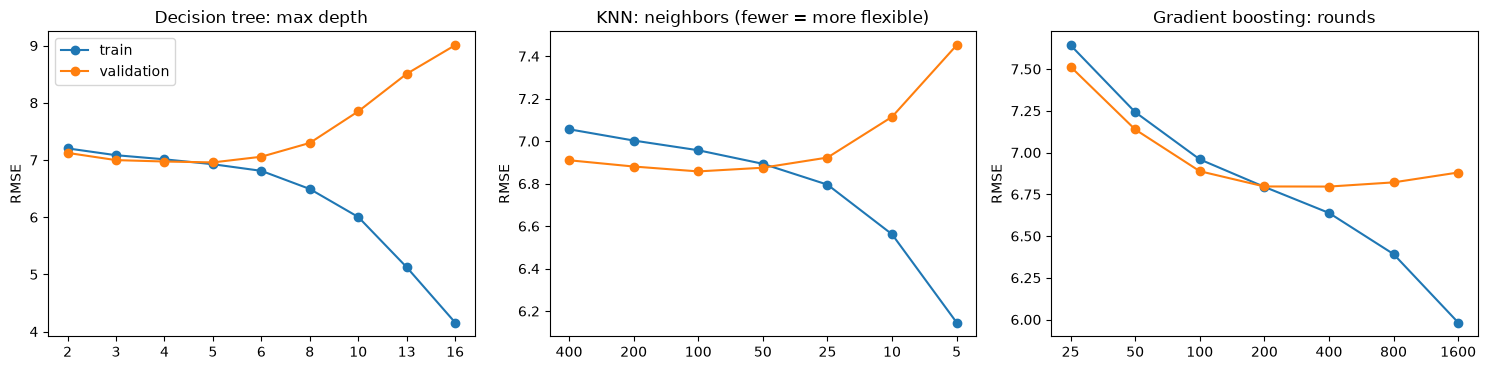

Decision tree: max depth,2,3,4,5,6,8,10,13,16
train,7.20,7.08,7.01,6.93,6.81,6.49,6.00,5.13,4.16
validation,7.12,7.00,6.97,6.96,7.06,7.30,7.85,8.51,9.01


KNN: neighbors (fewer = more flexible),400,200,100,50,25,10,5
train,7.06,7.00,6.96,6.89,6.80,6.56,6.15
validation,6.91,6.88,6.86,6.88,6.92,7.11,7.45


Gradient boosting: rounds,25,50,100,200,400,800,1600
train,7.64,7.24,6.96,6.79,6.64,6.39,5.98
validation,7.51,7.14,6.89,6.80,6.80,6.82,6.88


In [9]:
def train_valid_rmse(model):
    "Mean train and validation RMSE over the CV folds."
    rows = []
    for season, train, valid in cv_folds(train_features):
        fitted = clone(model).fit(train_features.loc[train, ALL_FEATURES], train_features.loc[train, TARGET])
        rows.append({name: np.sqrt(((fitted.predict(train_features.loc[idx, ALL_FEATURES]) - train_features.loc[idx, TARGET]) ** 2).mean())
                     for name, idx in [("train", train), ("validation", valid)]})
    return pd.DataFrame(rows).mean()


def complexity_curve(make_model, values):
    curve = Parallel(n_jobs=-1)(delayed(train_valid_rmse)(make_model(v)) for v in values)
    return pd.DataFrame(curve, index=values)


boosting_shape = {k: v for k, v in member_params["Gradient boosting"].items() if k != "max_iter"}
COMPLEXITY_CURVES = {
    "Decision tree: max depth": complexity_curve(
        lambda d: DecisionTreeRegressor(max_depth=d, random_state=SEED), [2, 3, 4, 5, 6, 8, 10, 13, 16]),
    "KNN: neighbors (fewer = more flexible)": complexity_curve(
        lambda k: scaled(KNeighborsRegressor(n_neighbors=k)), [400, 200, 100, 50, 25, 10, 5]),
    "Gradient boosting: rounds": complexity_curve(
        lambda n: make_boosting(**{**boosting_shape, "max_iter": n}), [25, 50, 100, 200, 400, 800, 1600]),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (title, curve) in zip(axes, COMPLEXITY_CURVES.items()):
    ax.plot(range(len(curve)), curve["train"], marker="o", label="train")
    ax.plot(range(len(curve)), curve["validation"], marker="o", label="validation")
    ax.set_xticks(range(len(curve)), curve.index)
    ax.set_title(title)
    ax.set_ylabel("RMSE")
axes[0].legend()
plt.tight_layout()
plt.show()
for title, curve in COMPLEXITY_CURVES.items():
    display(curve.T.round(2).rename_axis(title, axis=1))

**What we see:**
- **Tree:** validation RMSE is best at depth 5 (6.96). By depth 16 the train error falls to 4.16 while validation rises to 9.01.
- **KNN:** best at 100 neighbors (6.86). At 5 neighbors, train is 6.15 and validation 7.45.
- **Boosting:** validation is flat from 200 to 400 rounds (6.80) and creeps up to 6.88 at 1,600 rounds while train falls to 5.98. Our 300 rounds sit in the flat part.
- Weekly points are noisy, so flexible models start fitting noise quickly. The tuned settings from 6.2 sit at or next to the validation minimum in each curve.

### 6.6 Where are the errors?
Out-of-fold predictions from the chosen setup (voting ensemble, refit every week), split by position and by week of the season.
Bias is the mean of prediction minus actual. The untuned Ridge is shown for comparison.

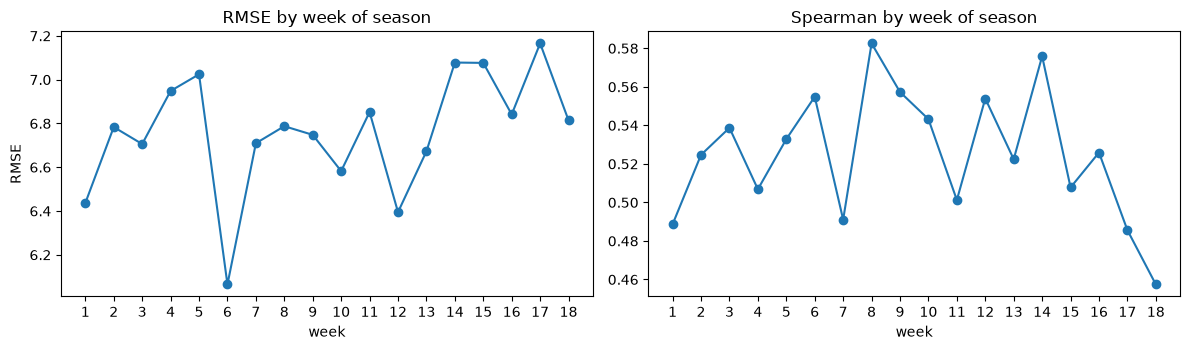

,player-weeks,mean points,rmse,mae,bias,spearman,ridge rmse,ridge spearman
QB,1726.0,14.680,7.457,5.976,-0.152,0.486,7.542,0.473
RB,2025.0,12.336,7.295,5.718,-0.282,0.473,7.341,0.464
WR,4927.0,9.535,6.958,5.326,-0.087,0.553,6.989,0.544
TE,2529.0,6.336,5.289,3.908,-0.157,0.588,5.321,0.577


,player-weeks,mean points,rmse,mae,bias,spearman,ridge rmse,ridge spearman
weeks 1-4,2691.0,9.711,6.722,5.136,0.010,0.515,6.747,0.508
weeks 5-18,8516.0,10.239,6.780,5.189,-0.198,0.528,6.828,0.517


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
rmse,6.436,6.784,6.706,6.948,7.024,6.065,6.710,6.787,6.748,6.582,6.852,6.395,6.673,7.078,7.077,6.841,7.166,6.814
spearman,0.489,0.525,0.539,0.507,0.533,0.555,0.491,0.583,0.557,0.543,0.501,0.554,0.522,0.576,0.508,0.526,0.486,0.457


In [10]:
chosen_oof = recency_oof[("Voting", "refit every week")]
ridge_oof = cross_validate(ridge, train_features, ALL_FEATURES)[1]
cv_rows = train_features[chosen_oof.notna()].assign(pred=chosen_oof, ridge_pred=ridge_oof)
cv_rows["error"] = cv_rows["pred"] - cv_rows[TARGET]


def error_summary(rows):
    scores = evaluate(rows, rows["pred"])
    return pd.Series({"player-weeks": len(rows), "mean points": rows[TARGET].mean(), "rmse": scores["rmse"],
                      "mae": scores["mae"], "bias": rows["error"].mean(), "spearman": scores["spearman"],
                      "ridge rmse": evaluate(rows, rows["ridge_pred"])["rmse"],
                      "ridge spearman": evaluate(rows, rows["ridge_pred"])["spearman"]})


errors_by_position = pd.DataFrame({p: error_summary(cv_rows[cv_rows["position"] == p]) for p in POSITIONS}).T
errors_by_week = pd.DataFrame({w: error_summary(rows) for w, rows in cv_rows.groupby("week")}).T
errors_by_stage = pd.DataFrame({name: error_summary(cv_rows[cv_rows["week"].between(lo, hi)])
                                for name, (lo, hi) in {"weeks 1-4": (1, 4), "weeks 5-18": (5, 18)}.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
errors_by_week["rmse"].plot(ax=axes[0], marker="o", title="RMSE by week of season", xlabel="week", ylabel="RMSE")
errors_by_week["spearman"].plot(ax=axes[1], marker="o", title="Spearman by week of season", xlabel="week")
for ax in axes:
    ax.set_xticks(errors_by_week.index)
plt.tight_layout()
plt.show()
display(errors_by_position.round(3), errors_by_stage.round(3), errors_by_week[["rmse", "spearman"]].T.round(3))

**What we see:**
- **By position:** point error is largest for QB (RMSE 7.46) and RB (7.30) and smallest for TE (5.29), who also score the least (6.3 points on average). Ranking is easiest for TE (Spearman 0.588) and WR (0.553) and hardest for RB (0.473) and QB (0.486).
- **Bias:** slightly negative everywhere (-0.09 to -0.28 points), so we under-predict a little, most for RB.
- **By week:** week 1 ranks poorly (Spearman 0.489, no games yet that season), and the last two weeks are the worst (0.486 and 0.457), when teams rest or lose starters. RMSE moves between 6.1 and 7.2 with no clear trend.
- Early weeks (1-4) rank slightly worse than later weeks (0.515 vs. 0.528) with about the same RMSE (6.72 vs. 6.78).
- Voting beats the untuned Ridge in every position and in both parts of the season.

### 6.7 Model comparison
All results in one table, best rank correlation first. The last row of 6.4 (voting, refit every week) is the chosen setup.

In [11]:
comparison = pd.concat([
    bar_to_beat.rename(index={"Ridge, untuned (5.8)": "Ridge, untuned"}),
    best_per_model.drop(columns="params"),
    combine_results.loc[["Voting (average of the three)", "Stacking (Ridge on top of the three)"], bar_to_beat.columns],
    pd.DataFrame({"Voting, refit every week (chosen)":
                  evaluate(train_features[chosen_oof.notna()], chosen_oof[chosen_oof.notna()])}).T,
]).sort_values(SELECT_METRIC, ascending=False).round(4)
comparison

,rmse,mae,spearman,top12_hit_rate
"Voting, refit every week (chosen)",6.7658,5.1766,0.5251,0.4888
Voting (average of the three),6.7651,5.1705,0.5247,0.4900
Stacking (Ridge on top of the three),6.7681,5.1810,0.5246,0.4919
MLP,6.7801,5.1746,0.5227,0.4977
Polynomial (degree 2) + Lasso,6.7937,5.2131,0.5190,0.4896
Gradient boosting,6.7919,5.2113,0.5189,0.4888
SVM (RBF kernel),6.8673,5.1250,0.5165,0.4927
Lasso,6.8025,5.1929,0.5157,0.4888
Ridge,6.8056,5.1942,0.5151,0.4900
"Ridge, untuned",6.8090,5.1939,0.5146,0.4896


**What we see:**
- **Chosen model:** the voting ensemble (Lasso + gradient boosting + MLP), trained on all earlier seasons with equal weights and refit every week: RMSE 6.766, MAE 5.177, Spearman 0.525, top-12 hit rate 0.489.
- Against the last-3 average it cuts RMSE by 0.83 and adds 0.10 Spearman. Against the untuned Ridge the gain is small: RMSE -0.043, Spearman +0.011.
- The top-12 hit rate does not improve (0.489 vs. 0.490 for Ridge). The gain is in ordering the whole list, not in who lands in the top 12.
- So most of the predictive power comes from the features (section 5); model choice and tuning add a small, consistent gain on top.

### Predictions handed to later phases (keep this the last part of section 6)
Tiers (section 7), clustering (section 8), and the final test (section 9) read the regression's out-of-fold predictions
and settings from two files. `REGRESSION_CHOICE` and `make_regression_model()` describe the chosen model; section 9 reuses both.
- `preds_regression.parquet`: one prediction per player-week in the CV seasons (2022-2024), made by a model that only saw games before that week
- `regression_choice.json`: the model and settings, so section 9 can rebuild the same model for 2025

In [12]:
import json

REGRESSION_CHOICE = {
    "status": "final",
    "model": "Voting (Lasso + gradient boosting + MLP)",
    "params": member_params,                    # each member's tuned settings from 6.2
    "features": ALL_FEATURES,
    "training_window": "all seasons before the predicted week",
    "sample_weight_half_life_seasons": None,    # None = every season counts the same
    "refit": "every week",
}


def make_regression_model(choice):
    return make_vote(choice["params"])


def save_regression_outputs(data, choice):
    scores, oof = cross_validate_recency(make_regression_model(choice), data, choice["features"],
                                         half_life=choice["sample_weight_half_life_seasons"],
                                         refit_weekly=choice["refit"] == "every week")
    scored = oof.notna()
    preds = data.loc[scored, KEY + ["position"]].assign(pred=oof[scored], model=choice["model"])
    preds.to_parquet(PROCESSED_DIR / "preds_regression.parquet", index=False)
    (PROCESSED_DIR / "regression_choice.json").write_text(json.dumps(choice, indent=2))
    return preds, scores


regression_preds, regression_scores = save_regression_outputs(train_features, REGRESSION_CHOICE)
assert np.allclose(regression_preds["pred"], chosen_oof[chosen_oof.notna()]), "published predictions differ from 6.4"
print(f"Saved {len(regression_preds):,} out-of-fold predictions "
      f"({regression_preds['season'].min()}-{regression_preds['season'].max()}), status: {REGRESSION_CHOICE['status']}")
print("Member settings:", REGRESSION_CHOICE["params"])
pd.Series(regression_scores).round(4).to_frame("CV score")

Saved 11,207 out-of-fold predictions (2022-2024), status: final
Member settings: {'Lasso': {'alpha': 0.01}, 'Gradient boosting': {'max_iter': 300, 'learning_rate': 0.02, 'max_leaf_nodes': 8, 'min_samples_leaf': 40}, 'MLP': {'hidden_layer_sizes': (64, 32), 'alpha': 30}}


,CV score
rmse,6.7658
mae,5.1766
spearman,0.5251
top12_hit_rate,0.4888


**What we see:**
- 11,207 out-of-fold predictions for 2022-2024 with status `final`. The scores equal the chosen row in 6.7 (RMSE 6.766, Spearman 0.525), and the cell checks that the saved predictions match the ones analyzed in 6.6.
- Sections 7 and 8 read these files, so they pick up the final model when the notebook is rerun.